# Precipitation Crash Correlation
##### For precipitation crash correlation, we will narrow our focus down to comparing the data for precipitation and vehicle collisions for Prince George's County only

In [3]:
# import needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

##### 1. We will load the raw crash reports for 2019-2023 to a pandas dataframe.
- We will only keep the columns that we need: report number, county of crash, and crash date
- We will also convert the crash date column into datetime format so it is easier to work with, and coerce all errors to NaT

In [4]:
RAW = "maryland_crash_data/raw"
frames = [pd.read_csv(f"{RAW}/CrashMap_REPORT_{y}.csv", low_memory=False,
                      usecols=["Reportnumber", "CountyOfCrash", "Crashdate"])
          for y in range(2019, 2024)]
crashes = pd.concat(frames, ignore_index=True)

# Convert the "Crashdate" column to datetime format, coercing errors to NaT
crashes["Crashdate"] = pd.to_datetime(crashes["Crashdate"], errors="coerce")

##### 2. We will only keep Prince George's County data and total up the crashes per day

In [5]:
# Keep only Prince George's County and count crashes per day
pg = crashes[crashes["CountyOfCrash"] == "Prince George's"]
daily_crashes = (pg["Crashdate"].dt.normalize().value_counts()
                 .rename_axis("date").rename("crashes").reset_index())

##### 3. We will merge the Prince George's daily precipitation data with the Prince George's daily crashes data
- We will load the "county_daily_precipitation_2019_2023.csv" file into a pandas dataframe "rain"
- "rain" is then merged with "crashes" to create daily
- We save the merged data into "pg_daily_precipitation_crashes_2019_2023.csv"

In [6]:
# Load the daily rain table and merge by date
rain = pd.read_csv("county_daily_precipitation_2019_2023.csv", parse_dates=["date"])
daily = rain.merge(daily_crashes, on="date", how="left")
daily["crashes"] = daily["crashes"].fillna(0).astype(int)   # days with no crashes are 0

daily.to_csv("pg_daily_precipitation_crashes_2019_2023.csv", index=False)

##### 4. Summary statistics and outliers
- We check the distribution of daily crashes and rain before testing
- Outliers are flagged with the 1.5 × IQR rule

       precipitation_mean_inches   crashes
count                   1826.000  1826.000
mean                       0.130    53.763
std                        0.310    11.930
min                        0.000    16.000
25%                        0.000    46.000
50%                        0.001    54.000
75%                        0.088    62.000
max                        2.993   107.000
Percentage of days with zero rain: 48.0%
Outliers: below 22 crashes per day or above 86 crashes per day. 19 days flagged as outliers.


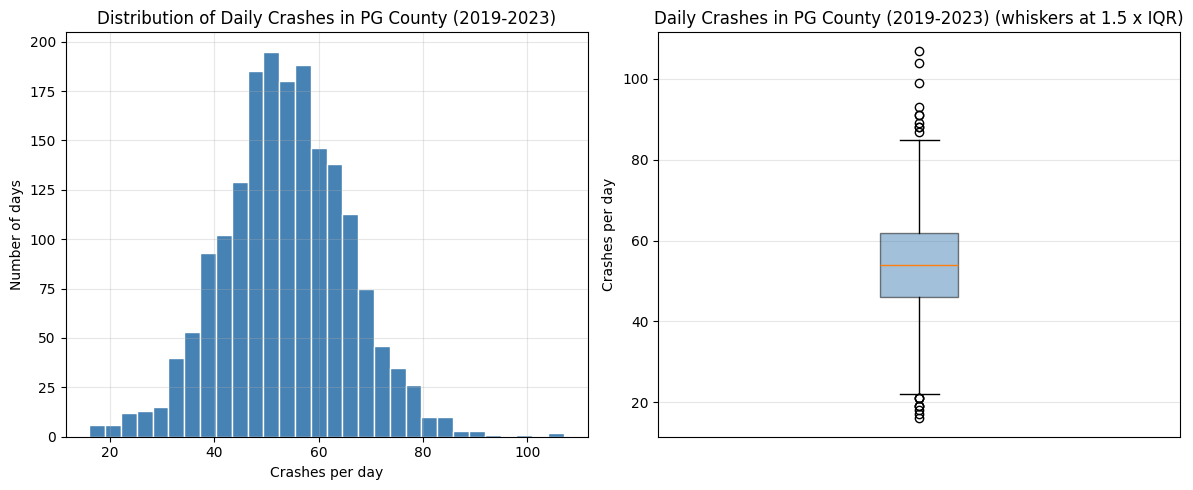

In [16]:
# Summary statistics for daily rain and daily crashes
print(daily[["precipitation_mean_inches", "crashes"]].describe().round(3))
print(f"Percentage of days with zero rain: {round((daily['precipitation_mean_inches'] == 0).mean(), 3)*100}%")

# Outliers in daily crashes using the 1.5 x IQR rule
q1, q3 = daily["crashes"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = daily[(daily["crashes"] < low) | (daily["crashes"] > high)]
print(f"Outliers: below {low:.0f} crashes per day or above {high:.0f} crashes per day. {len(outliers)} days flagged as outliers.")

# Histogram of daily crashes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(daily["crashes"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Daily Crashes in PG County (2019-2023)")
axes[0].set_xlabel("Crashes per day")
axes[0].set_ylabel("Number of days")
axes[0].grid(alpha=0.3)

# Boxplot of daily crashes
axes[1].boxplot(daily["crashes"], patch_artist=True,
                boxprops=dict(facecolor="steelblue", alpha=0.5))
axes[1].set_title("Daily Crashes in PG County (2019-2023) (whiskers at 1.5 x IQR)")
axes[1].set_ylabel("Crashes per day")
axes[1].set_xticks([])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### 5. We will then calculate the Pearson's Correlation and Spearman Correlation
- Significance Level: α = 0.05
- Pearson correlation
    - H₀ (null): There is no linear association between daily precipitation and daily crashes in Prince George’s County.
    - Hₐ (alternative): There is a linear association between daily precipitation and daily crashes.
- Spearman correlation
    - H₀: There is no monotonic association between daily precipitation and daily crashes.
    - Hₐ: There is a monotonic association between daily precipitation and daily crashes.

In [13]:
# Correlations with p-values
x = daily["precipitation_mean_inches"]
y = daily["crashes"]
r, p_r = pearsonr(x, y)
rho, p_s = spearmanr(x, y)
print(f"Pearson r = {r:.3f} (p = {p_r:.4g})")
print(f"Spearman rho = {rho:.3f} (p = {p_s:.4g})")

Pearson r = 0.114 (p = 1.091e-06)
Spearman rho = 0.062 (p = 0.007764)


This results in a Pearson r of 0.114 and a Spearman rho of 0.062

- Decision
- Pearson: p ≈ 1.1 × 10⁻⁶, which is less than 0.05
    - We can reject the null hypothesis
- Spearman: p ≈ 0.008, which is less than 0.05
    - We can reject the null hypothesis

Explanation

- The association of precipitation and crashes is positive but very weak
    - Rain explains about 1% of the variation in daily crashes (r² ≈ 0.013)
- Because the sample is large (n = 1,826 days), even small effects reach statistical significance, so the effect size should be interpreted alongside the p-value
- The result shows that the two measures move together slightly, but does not prove that rain causes crashes.
- The p-values assume independence, but days aren’t fully independent as weather can carry over from one day to the next. This is a limitation.

##### 6. We then generate a scatter plot for data visualization
- Each blue dot shows crashes per day vs precipitation that day
- The line of best fit has a positive slope with points spread widely around it, showing that there is a slight upward trend in crashes on wetter days, with a lot of day to day variation

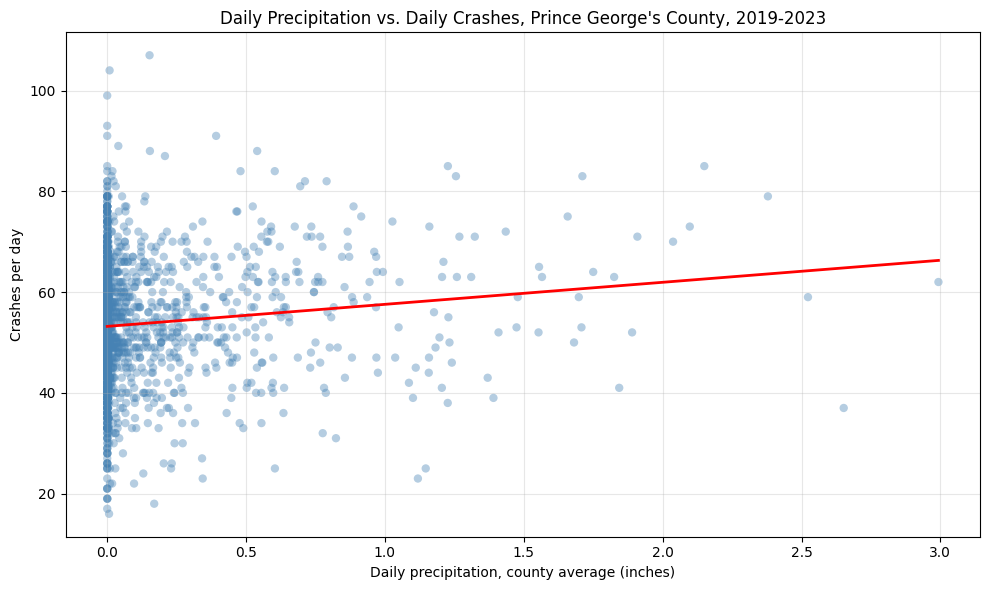

In [14]:
# Scatter plot with a fitted line
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, alpha=0.4, color="steelblue", edgecolor="none")
slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, intercept + slope * xs, color="red", linewidth=2)
ax.set_title("Daily Precipitation vs. Daily Crashes, Prince George's County, 2019-2023")
ax.set_xlabel("Daily precipitation, county average (inches)")
ax.set_ylabel("Crashes per day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()